# **Topicos de datos y Texto** 
#### Profesor: Andres Eduardo Rangel Jimenez

## Support Vector Machines (SVM)

### Algoritmo de máquina de vectores de soporte (SVM)

SVM es un algoritmo interesante y los conceptos son relativamente simples. El clasificador separa los puntos de datos utilizando un hiperplano con la mayor cantidad de margen. Es por eso que un clasificador SVM también se conoce como clasificador discriminativo. SVM encuentra un hiperplano óptimo que ayuda a clasificar nuevos puntos de datos.

Una máquina de vectores de soporte (SVM) es un algoritmo de aprendizaje automático supervisado que se utiliza tanto para tareas de clasificación como de regresión.. Pueden manejar fácilmente múltiples variables continuas y categóricas. El objetivo principal del algoritmo SVM es identificar el hiperplano óptimo en un espacio N-dimensional que pueda separar eficazmente los puntos de datos en diferentes clases en el espacio de características. El algoritmo garantiza que se maximice el margen entre los puntos más cercanos de diferentes clases, conocidos como vectores de soporte. La idea central de las máquinas de vectores de soporte es encontrar un hiperplano marginal máximo (MMH) que divida mejor el conjunto de datos en clases.En otras palabras, dados los datos de entrenamiento etiquetados (aprendizaje supervisado), el algoritmo genera un hiperplano óptimo que clasifica los nuevos ejemplos.

Las SVM son particularmente eficaces porque se centran en encontrar el hiperplano de separación máximo entre las diferentes clases en la característica de destino, lo que las hace robustas tanto para la clasificación binaria como para la multiclase. En este esquema, exploraremos el algoritmo de máquina de vectores de soporte (SVM), sus aplicaciones y cómo maneja de manera eficaz la clasificación lineal y no lineal, así como las tareas de regresión y detección de valores atípicos.

La dimensión del hiperplano depende de la cantidad de características. Por ejemplo, si hay dos características de entrada, el hiperplano es simplemente una línea, y si hay tres características de entrada, el hiperplano se convierte en un plano 2-D. A medida que la cantidad de características aumenta más allá de tres, también aumenta la complejidad de visualización del hiperplano.

#### Ejercicio de simulacion

Considere dos variables independientes, x1 y x2, y una variable dependiente representada como un círculo amarillo o un círculo rojo.

En este escenario, el hiperplano es una línea porque estamos trabajando con dos características (x1 y x2). -Hay múltiples líneas (o hiperplanos) que pueden separar los puntos de datos. -El desafío es determinar el mejor hiperplano que maximice el margen de separación entre los círculos rojo y amarillo.  Pero venimos hablado de un hiperplano, que es?:


Un hiperplano es una generalización del concepto de “plano” a dimensiones más altas.
En 2 dimensiones (2D), un hiperplano es una recta que divide el plano en dos partes.
En 3 dimensiones (3D), un hiperplano es un plano que divide el espacio en dos partes.
En n dimensiones, un hiperplano es un subespacio de dimensión  n−1 que divide ese espacio en dos mitades.

De la figura anterior se desprende claramente que existen múltiples líneas (nuestro hiperplano aquí es una línea porque solo estamos considerando dos características de entrada x1, x2) que separan nuestros puntos de datos o realizan una clasificación entre círculos rojos y amarillos . Entonces, ¿cómo elegimos la mejor línea o, en general, el mejor hiperplano que separa nuestros puntos de datos?


In [4]:
##Paquetes que vamos a usar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import os
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches
import matplotlib.colors as colors
import seaborn as sns
from sklearn import datasets
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import  accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn import preprocessing
from sklearn.preprocessing import scale
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
from sklearn import preprocessing
import matplotlib.colors as colors
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn import metrics
from sklearn import svm
from sklearn.datasets import make_circles
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.datasets import make_blobs

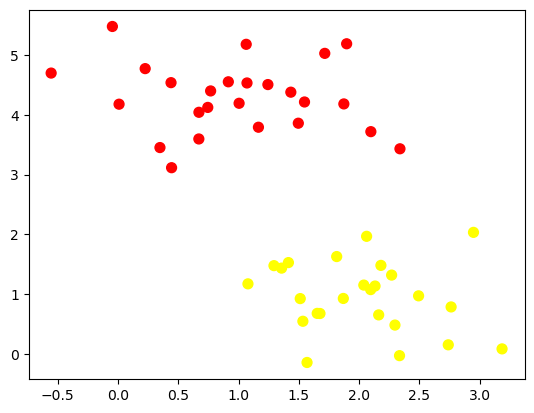

In [6]:
# creating datasets X containing n_samples
# Y containing two classes
X, y = make_blobs(n_samples=50, centers=2,
                  random_state=0, cluster_std=0.60)
# plotting scatters 

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')


#tomado de https://jakevdp.github.io/PythonDataScienceHandbook/05.07-support-vector-machines.html

**¿Cómo funciona el algoritmo de la máquina de vectores de soporte?** Una opción razonable para el mejor hiperplano en una máquina de vectores de soporte (SVM) es la que maximiza el margen de separación entre las dos clases. El hiperplano de margen máximo, también conocido como margen duro, se selecciona en función de maximizar la distancia entre el hiperplano y el punto de datos más cercano en cada lado.

Un clasificador discriminativo lineal intentaría dibujar una línea recta que separara los dos conjuntos de datos y, de ese modo, crear un modelo de clasificación. Para datos bidimensionales como los que se muestran aquí, esta es una tarea que podríamos hacer a mano. Pero inmediatamente vemos un problema: ¡hay más de una línea divisoria posible que puede discriminar perfectamente entre las dos clases!

Podemos dibujarlas de la siguiente manera:

Se trata de tres separadores muy diferentes que, sin embargo, discriminan perfectamente entre estas muestras. Dependiendo de cuál elijas, a un nuevo punto de datos (por ejemplo, el marcado con la "X" en este gráfico) se le asignará una etiqueta diferente. Evidentemente, nuestra simple intuición de "trazar una línea entre clases" no es suficiente y tenemos que pensar un poco más a fondo.

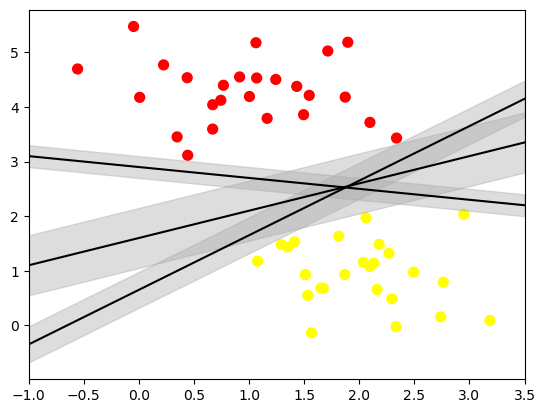

In [8]:
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
                     color='#AAAAAA', alpha=0.4)

plt.xlim(-1, 3.5);

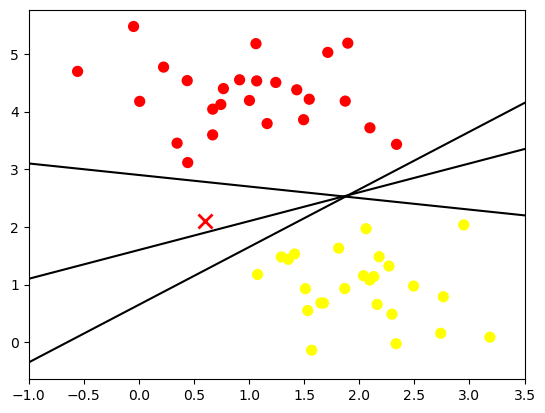

In [12]:
import numpy as np
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.plot([0.6], [2.1], 'x', color='red', markeredgewidth=2, markersize=10)

for m, b in [(1, 0.65), (0.5, 1.6), (-0.2, 2.9)]:
    plt.plot(xfit, m * xfit + b, '-k')

plt.xlim(-1, 3.5);

**Support Vector Machines: Maximizing the Margin**

Por lo tanto, elegimos el hiperplano cuya distancia desde él hasta el punto de datos más cercano en cada lado sea máxima. Si existe dicho hiperplano, se lo conoce como hiperplano de margen máximo/margen duro. Lo que hacen las máquinas de vectores de soporte no es solo dibujar una línea entre dos clases, sino considerar una región alrededor de la línea de un ancho determinado. Aquí hay un ejemplo de cómo puede verse:

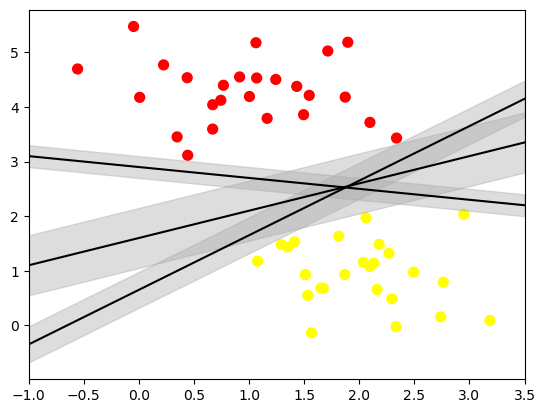

In [15]:
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
                     color='#AAAAAA', alpha=0.4)

plt.xlim(-1, 3.5);

**Fitting a support vector machine**


Veamos el resultado de un ajuste real a estos datos: utilizaremos el clasificador de vectores de soporte de Scikit-Learn para entrenar un modelo SVM con estos datos. Por el momento, utilizaremos un núcleo lineal y estableceremos el parámetro C en un número muy grande (discutiremos el significado de estos en más profundidad en un momento).

Esta es la línea divisoria que maximiza el margen entre los dos conjuntos de puntos. Observe que algunos de los puntos de entrenamiento apenas tocan el margen: están indicados por los círculos negros en esta figura. Estos puntos son los elementos fundamentales de este ajuste y se conocen como vectores de soporte, y dan nombre al algoritmo. En Scikit-Learn, la identidad de estos puntos se almacena en el atributo support_vectors_ del clasificador:

Una clave para el éxito de este clasificador es que, para el ajuste, solo importa la posición de los vectores de soporte; los puntos más alejados del margen que estén en el lado correcto no modifican el ajuste. Técnicamente, esto se debe a que estos puntos no contribuyen a la función de pérdida utilizada para ajustar el modelo, por lo que su posición y número no importan siempre que no crucen el margen.

Podemos ver esto, por ejemplo, si graficamos el modelo aprendido a partir de los primeros 60 puntos y los primeros 120 puntos de este conjunto de datos:

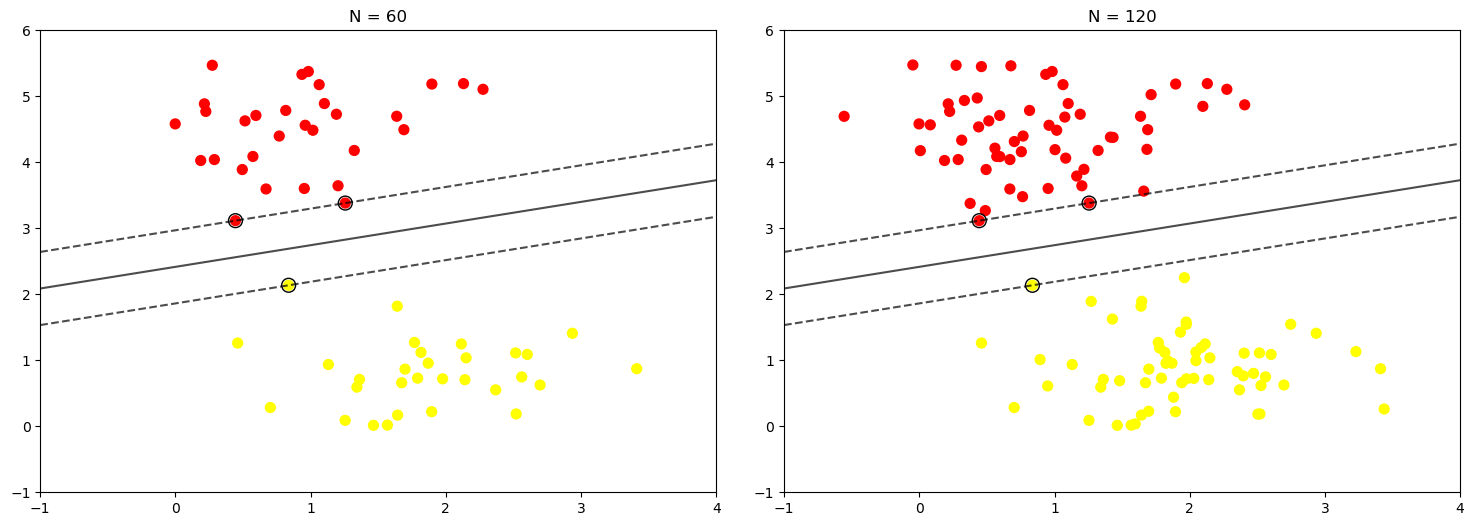

In [10]:
# Función auxiliar para graficar la frontera de decisión
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # Crear malla
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # Dibujar fronteras y márgenes
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.7,
               linestyles=['--', '-', '--'])

    # Dibujar vectores de soporte
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=100, facecolors='none', edgecolors='k')

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

# Función principal
def plot_svm(N=10, ax=None):
    X, y = make_blobs(n_samples=200, centers=2,
                      random_state=0, cluster_std=0.60)
    X = X[:N]
    y = y[:N]
    model = SVC(kernel='linear', C=1E10)
    model.fit(X, y)
    
    ax = ax or plt.gca()
    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(model, ax)

# Ejecutar para N=60 y N=120
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title('N = {0}'.format(N))

plt.show()


En el panel izquierdo, vemos el modelo y los vectores de soporte para 60 puntos de entrenamiento. En el panel derecho, hemos duplicado la cantidad de puntos de entrenamiento, pero el modelo no ha cambiado: los tres vectores de soporte del panel izquierdo siguen siendo los vectores de soporte del panel derecho. Esta insensibilidad al comportamiento exacto de los puntos distantes es una de las fortalezas del modelo SVM.

Si está ejecutando este cuaderno en vivo, puede usar los widgets interactivos de IPython para ver esta característica del modelo SVM de forma interactiva:

#### Ajuste de hiperparámetros

Kernel: la función principal del kernel es transformar los datos de entrada del conjunto de datos dados en la forma requerida. Existen varios tipos de funciones, como la función de base lineal, polinómica y radial (RBF). La función polinómica y la función de base radial son útiles para hiperplanos no lineales. Los kernels polinómicos y RBF calculan la línea de separación en la dimensión superior. En algunas de las aplicaciones, se sugiere utilizar un kernel más complejo para separar las clases que son curvas o no lineales. Esta transformación puede generar clasificadores más precisos.

Regularización: parámetro de regularización en el parámetro C de Scikit-learn de Python que se utiliza para mantener la regularización. Aquí, C es el parámetro de penalización, que representa la clasificación errónea o el término de error.  Un valor menor de C crea un hiperplano de margen pequeño y un valor mayor de C crea un hiperplano de margen mayor.

Gamma: un valor más bajo de Gamma se ajustará de forma flexible al conjunto de datos de entrenamiento, mientras que un valor más alto de Gamma se ajustará exactamente al conjunto de datos de entrenamiento, lo que provoca un sobreajuste. En otras palabras, se puede decir que un valor bajo de Gamma considera solo los puntos cercanos al calcular la línea de separación, mientras que un valor de Gamma considera todos los puntos de datos al calcular la línea de separación.

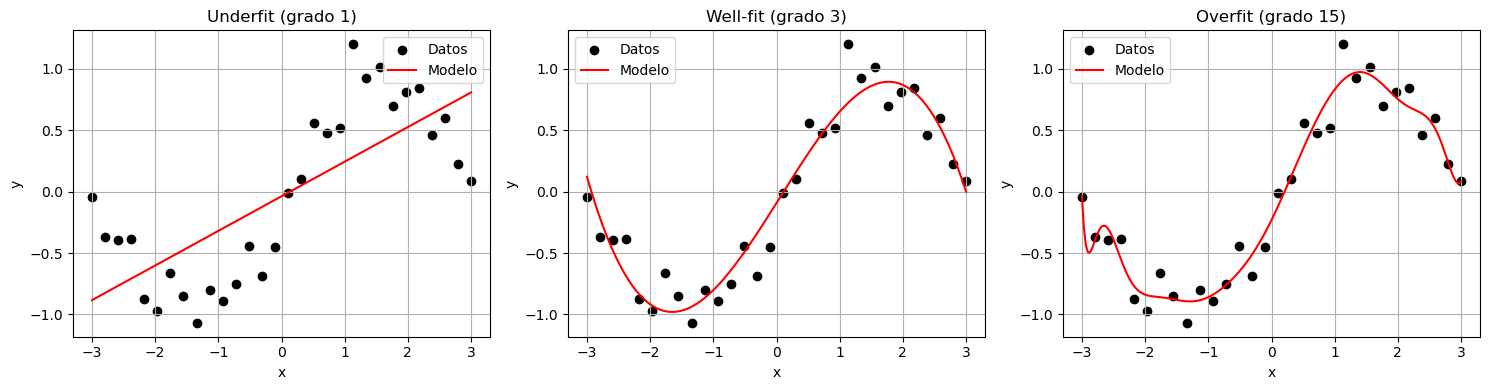

In [13]:
# Generar datos simulados
np.random.seed(42)
X = np.linspace(-3, 3, 30).reshape(-1, 1)
y = np.sin(X) + np.random.normal(0, 0.2, X.shape)  # datos con ruido

# Diferentes grados de polinomio
degrees = [1, 3, 15]  # underfit, well-fit, overfit
titles = ["Underfit (grado 1)", "Well-fit (grado 3)", "Overfit (grado 15)"]

plt.figure(figsize=(15, 4))

for i, degree in enumerate(degrees):
    # Transformar las variables
    poly = PolynomialFeatures(degree=degree)
    X_poly = poly.fit_transform(X)
    
    # Ajustar modelo
    model = LinearRegression()
    model.fit(X_poly, y)
    
    # Predicciones en un rango más fino
    X_test = np.linspace(-3, 3, 200).reshape(-1, 1)
    X_test_poly = poly.transform(X_test)
    y_pred = model.predict(X_test_poly)
    
    # Graficar
    plt.subplot(1, 3, i+1)
    plt.scatter(X, y, color="black", label="Datos")
    plt.plot(X_test, y_pred, color="red", label="Modelo")
    plt.title(titles[i])
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

#### Cambios la frontera de decisión de un SVM cuando se modifica el parametro  gamma

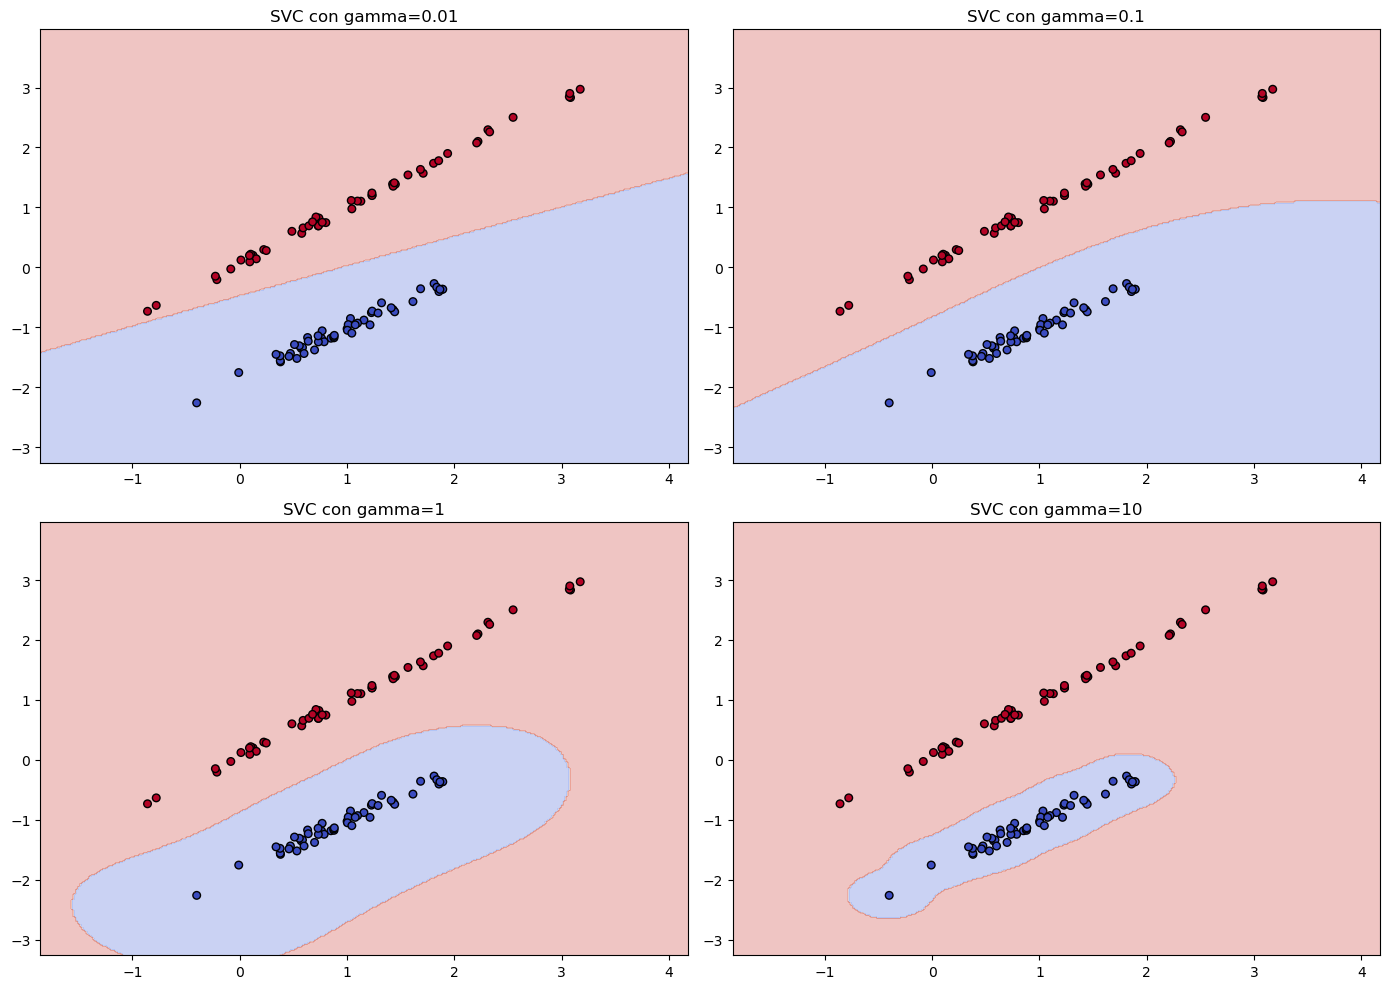

In [15]:
# Generar datos de ejemplo (2 clases en 2D)
X, y = datasets.make_classification(
    n_features=2, n_redundant=0, n_informative=2,
    n_clusters_per_class=1, n_samples=100, random_state=42
)

# Valores de gamma a comparar
gammas = [0.01, 0.1, 1, 10]

plt.figure(figsize=(14, 10))

for i, g in enumerate(gammas, 1):
    # Entrenar SVM con RBF y gamma específico
    clf = SVC(kernel="rbf", gamma=g, C=1)
    clf.fit(X, y)
    
    # Crear malla para graficar fronteras de decisión
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    # Graficar región de decisión
    plt.subplot(2, 2, i)
    plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    plt.scatter(X[:, 0], X[:, 1], c=y, s=30, cmap=plt.cm.coolwarm, edgecolors="k")
    plt.title(f"SVC con gamma={g}")

plt.tight_layout()
plt.show()

**Mas alla de los limites lineales: Kernel, Núcleos de SVM**


Hasta ahora, estábamos hablando de datos linealmente separables (el grupo de bolas azules y bolas rojas se pueden separar mediante una línea recta/línea lineal). ¿Qué hacer si los datos no son linealmente separables?

El algoritmo SVM se implementa en la práctica mediante un núcleo. Un núcleo transforma un espacio de datos de entrada en la forma requerida. SVM utiliza una técnica llamada truco del núcleo. En este caso, el núcleo toma un espacio de entrada de baja dimensión y lo transforma en un espacio de mayor dimensión. En otras palabras, se puede decir que convierte un problema no separable en un problema separable al agregarle más dimensión. Es más útil en problemas de separación no lineal. El truco del núcleo le ayuda a construir un clasificador más preciso.

En los modelos SVM, podemos usar una versión de la misma idea. Para motivar la necesidad de kernels, veamos algunos datos que no son linealmente separables:

#### Linear kernel

En el kernel lineal, la función kernel toma la forma de una función lineal de la siguiente manera: kernel lineal: K(xi, xj) = xiT xj El kernel lineal se utiliza cuando los datos son linealmente separables. Esto significa que los datos se pueden separar utilizando una sola línea. Es uno de los kernels más comunes que se utilizan. Se utiliza principalmente cuando hay una gran cantidad de características en un conjunto de datos. El kernel lineal se utiliza a menudo para fines de clasificación de texto.

El entrenamiento con un kernel lineal suele ser más rápido, porque solo necesitamos optimizar el parámetro de regularización C. Cuando se entrena con otros kernels, también necesitamos optimizar el parámetro γ. Por lo tanto, realizar una búsqueda en cuadrícula generalmente llevará más tiempo.

####  Kernel polinomial
El kernel polinomial representa la similitud de los vectores (muestras de entrenamiento) en un espacio de características sobre polinomios de las variables originales. El kernel polinomial no solo analiza las características dadas de las muestras de entrada para determinar su similitud, sino también las combinaciones de las muestras de entrada.

Para polinomios de grado d, el kernel polinomial se define de la siguiente manera:

Kernel polinomial: K(xi, xj) = (γxiT xj + r)d, γ > 0

El kernel polinomial es muy popular en el procesamiento del lenguaje natural. El grado más común es d = 2 (cuadrático)

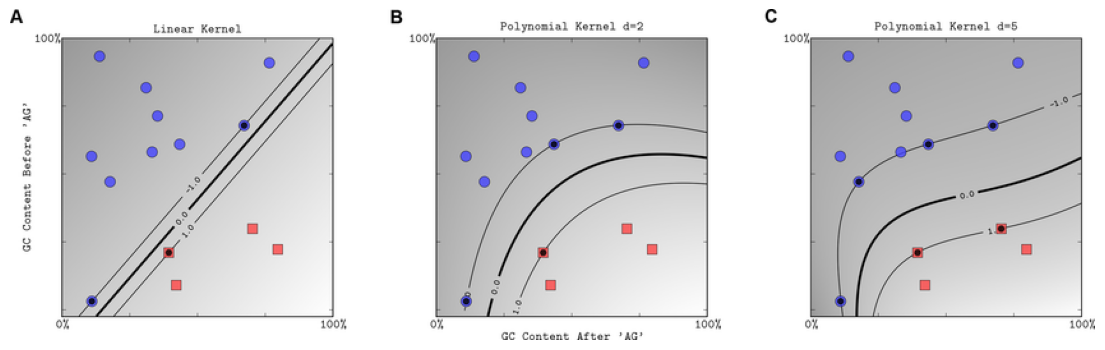

In [32]:
# importing pyplot and image from matplotlib 
import matplotlib.pyplot as plt 
import matplotlib.image as img 
# reading png image file 
im = img.imread('Capture19.png') 
  
plt.figure(figsize=(14, 14))  # Cambia los valores para ajustar el tamaño deseado
plt.axis('off')
plt.imshow(im)
plt.show()

- Polinomio de grado 2 (también llamado cuadrático):
Es aquel cuyo mayor exponente de  x es 2.
Forma general:
$$
P(x)=ax^2+bx+c
$$
donde  a≠0 b y  c son números reales.
- 
Polinomio de grado 5 (también llamado quintico o de quinto grado):
Es aquel cuyo mayor exponente x es 5.

Forma general:
$$
P(x)=ax^5+bx^4+cx^3+dx^3+ex+f
$$

#### Radial Basis  Kernel


El kernel de función de base radial (RBF) es un kernel de propósito general. Se utiliza cuando no tenemos conocimiento previo sobre los datos. 

#### Núcleo sigmoide

El núcleo sigmoide tiene su origen en las redes neuronales. Podemos usarlo como proxy para las redes neuronales. 

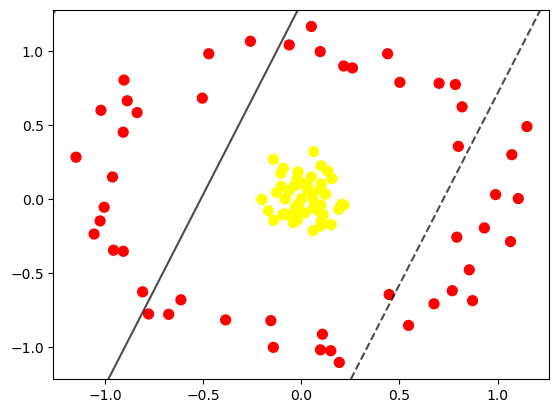

In [36]:
X, y = make_circles(100, factor=.1, noise=.1)

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False);


Está claro que ninguna discriminación lineal podrá jamás separar estos datos. Pero podemos extraer una lección de las regresiones de función base en En profundidad: Regresión lineal y pensar en cómo podríamos proyectar los datos en una dimensión superior de modo que un separador lineal fuera suficiente. Por ejemplo, una proyección simple que podríamos utilizar sería calcular una función base radial centrada en el grupo central:

##### Incluyo una nueva dimension r

In [40]:
r = np.exp(-(X ** 2).sum(1))

### Explicacion de la ultima linea de codigo: incorporando una dimension superior

X es un arreglo de dimensión ((n,2) porque los datos vienen de make_circles, simulacion que producen  puntos en 2D

##### Paso 1: elevar al cuadrado

In [44]:
# Mostrando  ecuación en LaTeX
from IPython.display import display, Math 
display(Math(r"X = \begin{bmatrix} x_{11} & x_{12} \\ x_{21} & x_{22} \\ \vdots & \vdots \\ x_{n1} & x_{n2} \end{bmatrix}"))

display(Math(r"X^{2} = \begin{bmatrix} x_{11}^2 & x_{12}^2 \\ x_{21}^2 & x_{22}^2 \\ \vdots & \vdots \\ x_{n1}^2 & x_{n2}^2 \end{bmatrix}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Paso 2. Sumar por filas (.sum(1)

In [47]:
display(Math(r"(X^2).sum(1) = \begin{bmatrix} x_{11}^2 + x_{12}^2 \\ x_{21}^2 + x_{22}^2 \\ \vdots \\ x_{n1}^2 + x_{n2}^2 \end{bmatrix}"))

<IPython.core.display.Math object>

##### Paso 3: aplicar el negativo y exponencial

Ahora tomamos cada suma y le aplicamos  exp(−⋅):

In [50]:
from IPython.display import display, Math

# Paso 3: aplicar negativo y exponencial
display(Math(r"r = \exp\Big(- (X^2).sum(1)\Big) = "
             r"\begin{bmatrix} "
             r"e^{-(x_{11}^2 + x_{12}^2)} \\ "
             r"e^{-(x_{21}^2 + x_{22}^2)} \\ "
             r"\vdots \\ "
             r"e^{-(x_{n1}^2 + x_{n2}^2)} "
             r"\end{bmatrix}"))

<IPython.core.display.Math object>

In [52]:
from IPython.display import display, Math

##### Interpretación



Cada punto 2D ($x_1$, $x_2$)  obtiene un valor adicional r que depende de su distancia al origen. Este valor decrece de manera exponencial conforme el punto se aleja del centro.

En efecto, estás construyendo una tercera dimensión:


In [55]:

display(Math("(x_1, x_2) \\mapsto (x_1, x_2, r)"))
display(Math("r = e^{-(x_1^2 + x_2^2)}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

El codigo  es parecido a aplicar un kernel radial (RBF) manualmente: se transforma el espacio 2D en un espacio de dimensión superior (3D en este caso), donde los datos circulares ya son separables linealmente.
En pocas palabras:El código está introduciendo una nueva característica no lineal  r, que actúa como una "altura" dependiente de la distancia al centro.
Esto permite que un hiperplano lineal en 3D se proyecte como una frontera circular en 2D.

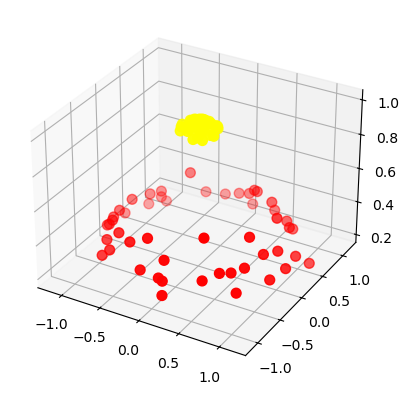

In [58]:
ax = plt.axes(projection='3d')

# Data for three-dimensional scattered points
ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn');


Podemos ver que con esta dimensión adicional, los datos se vuelven trivialmente separables linealmente, dibujando un plano de separación 

Aquí tuvimos que elegir y ajustar cuidadosamente nuestra proyección: si no hubiéramos centrado nuestra función de base radial en la ubicación correcta, no habríamos visto resultados tan limpios y linealmente separables. En general, la necesidad de hacer tal elección es un problema: nos gustaría encontrar de alguna manera automáticamente las mejores funciones de base para usar.

Una estrategia para este fin es calcular una función de base centrada en cada punto en el conjunto de datos y dejar que el algoritmo SVM filtre los resultados. Este tipo de transformación de función de base se conoce como transformación kernel, ya que se basa en una relación de similitud (o kernel) entre cada par de puntos.

Un problema potencial con esta estrategia (proyectar $N$ puntos en $N$ dimensiones) es que podría volverse muy intensiva computacionalmente a medida que $N$ crece. Sin embargo, gracias a un pequeño procedimiento conocido como el truco del núcleo, se puede realizar un ajuste de los datos transformados por el núcleo de manera implícita, es decir, sin construir nunca la representación $N$-dimensional completa de la proyección del núcleo. Este truco del núcleo está integrado en el SVM y es una de las razones por las que el método es tan potente.

En Scikit-Learn, podemos aplicar el SVM kernelizado simplemente cambiando nuestro núcleo lineal a un núcleo RBF (función de base radial), utilizando el hiperparámetro del modelo del núcleo:

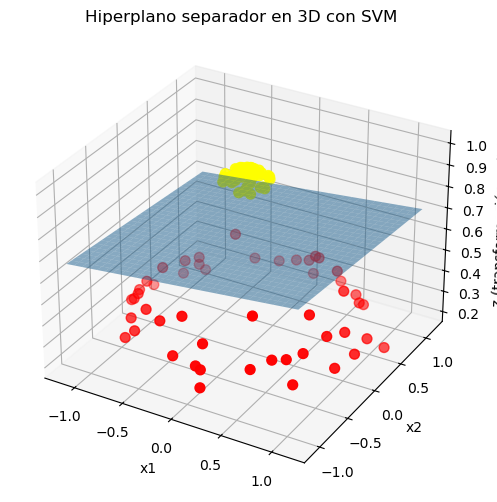

In [17]:
# Generar datos 2D
X, y = make_circles(100, factor=.1, noise=.1)

# Definir la tercera dimensión como una transformación radial
r = np.exp(-(X ** 2).sum(1)).reshape(-1, 1)
X3D = np.hstack([X, r])   # datos en 3D

# Entrenar un clasificador lineal en 3D
clf = SVC(kernel='linear')
clf.fit(X3D, y)

# Crear malla para graficar el hiperplano
xx, yy = np.meshgrid(np.linspace(X[:,0].min(), X[:,0].max(), 30),
                     np.linspace(X[:,1].min(), X[:,1].max(), 30))

# Ecuación del hiperplano: w1*x + w2*y + w3*z + b = 0  -> despejar z
w = clf.coef_[0]
b = clf.intercept_[0]
zz = (-w[0]*xx - w[1]*yy - b) / w[2]

# Gráfico 3D
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')

# Puntos
ax.scatter3D(X3D[:, 0], X3D[:, 1], X3D[:, 2], c=y, s=50, cmap='autumn')

# Plano separador
ax.plot_surface(xx, yy, zz, alpha=0.5)

ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("z (transformación radial)")
ax.set_title("Hiperplano separador en 3D con SVM")

plt.show()

**Tuning the SVM: Softening Margins**

Hasta ahora, nuestro análisis se ha centrado en conjuntos de datos muy limpios, en los que existe un límite de decisión perfecto. Pero, ¿qué sucede si sus datos tienen cierta superposición? Por ejemplo, puede tener datos como estos:

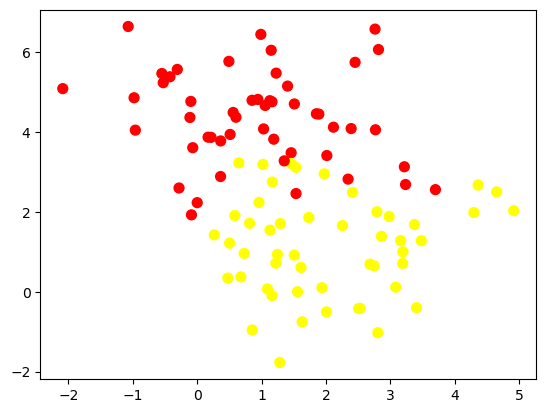

In [66]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=1.2)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn');

Para manejar este caso, la implementación de SVM tiene un factor de ajuste que "suaviza" el margen: es decir, permite que algunos de los puntos se deslicen hacia el margen si eso permite un mejor ajuste. La dureza del margen se controla mediante un parámetro de ajuste, conocido más comúnmente como $C$. Para $C$ muy grandes, el margen es duro y los puntos no pueden estar en él. Para $C$ más pequeños, el margen es más suave y puede crecer hasta abarcar algunos puntos.

El gráfico que se muestra a continuación ofrece una imagen visual de cómo un parámetro $C$ cambiante afecta el ajuste final, a través del suavizado del margen:

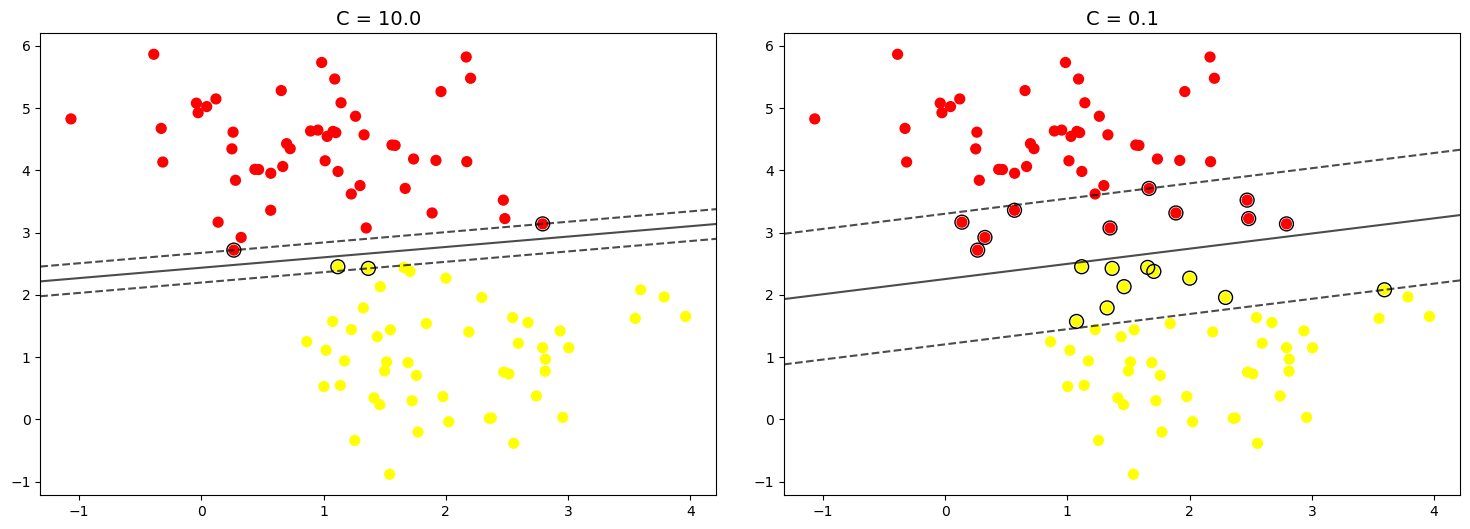

In [69]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=0.8)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel='linear', C=C).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    plot_svc_decision_function(model, axi)
    axi.scatter(model.support_vectors_[:, 0],
                model.support_vectors_[:, 1],
                s=300, lw=1, facecolors='none');
    axi.set_title('C = {0:.1f}'.format(C), size=14)

El valor óptimo del parámetro $C$ dependerá de su conjunto de datos y debe ajustarse mediante validación cruzada o un procedimiento similar (consulte Hiperparámetros y validación del modelo).

**Terminología de la máquina de vectores de soporte**

- Hiperplano: el hiperplano es el límite de decisión utilizado para separar los puntos de datos de diferentes clases en un espacio de características. Para la clasificación lineal, se trata de una ecuación lineal representada como wx+b=0.
- Vectores de soporte: los vectores de soporte son los puntos de datos más cercanos al hiperplano. Estos puntos son fundamentales para determinar el hiperplano y el margen en la máquina de vectores de soporte (SVM).
- Margen: el margen se refiere a la distancia entre el vector de soporte y el hiperplano. El objetivo principal del algoritmo SVM es maximizar este margen, ya que un margen más amplio generalmente da como resultado un mejor rendimiento de la clasificación.
- Núcleo: el núcleo es una función matemática utilizada en SVM para mapear los datos de entrada en un espacio de características de mayor dimensión. Esto permite que la SVM encuentre un hiperplano en los casos en los que los puntos de datos no se pueden separar linealmente en el espacio original. Las funciones de kernel comunes incluyen funciones lineales, polinómicas, de base radial (RBF) y sigmoideas.
- Un núcleo SVM básicamente agrega más dimensiones a un espacio de pocas dimensiones para facilitar la segregación de los datos. Convierte el problema inseparable en problemas separables agregando más dimensiones utilizando el truco del núcleo. Una máquina de vectores de soporte se implementa en la práctica mediante un núcleo. El truco del núcleo ayuda a crear un clasificador más preciso. Echemos un vistazo a los diferentes núcleos de la máquina de vectores de soporte.
- Margen duro: un margen duro se refiere al hiperplano de margen máximo que separa perfectamente los puntos de datos de diferentes clases sin ninguna clasificación errónea.
- Margen blando: cuando los datos contienen valores atípicos o no son perfectamente separables, SVM utiliza la técnica de margen blando. Este método introduce una variable de holgura para cada punto de datos para permitir algunas clasificaciones erróneas mientras se equilibra entre maximizar el margen y minimizar las violaciones.
- C: el parámetro C en SVM es un término de regularización que equilibra la maximización del margen y la penalización por clasificaciones erróneas. Un valor C más alto impone una penalización más estricta por las violaciones del margen, lo que genera un margen más pequeño pero menos clasificaciones erróneas.
- Pérdida de bisagra: la pérdida de bisagra es una función de pérdida común en SVM. Penaliza los puntos mal clasificados o las violaciones del margen y, a menudo, se combina con un término de regularización en la función objetivo.
- Problema dual: el problema dual en SVM implica resolver los multiplicadores de Lagrange asociados con los vectores de soporte. Esta formulación permite el uso del truco del núcleo y facilita un cálculo más eficiente.

Para una derivacion matematica de SVM vease: https://www.geeksforgeeks.org/support-vector-machine-algorithm/

**Support Vector Machine Summary**

Hemos visto aquí una breve introducción intuitiva a los principios que sustentan las máquinas de vectores de soporte. Estos métodos son un método de clasificación poderoso por varias razones:
.
- Debido a que solo se ven afectados por puntos cerca del margen, funcionan bien con datos de alta dimensión, incluso datos con más dimensiones que las muestras, lo que es un régimen desafiante para otros algoritmos.
- Su integración con métodos de kernel los hace muy versátiles, capaces de adaptarse a muchos tipos de datos.

Sin embargo, las SVM también tienen varias desventajas:

- Los resultados dependen en gran medida de una elección adecuada para el parámetro de suavizado $C$. Este debe elegirse cuidadosamente mediante una validación cruzada, que puede ser costosa a medida que los conjuntos de datos aumentan de tamaño.
- Los resultados no tienen una interpretación probabilística directa. Esto se puede estimar mediante una validación cruzada interna (consulte el parámetro de probabilidad de SVC), pero esta estimación adicional es costosa.

## Ejercicio 1. Clasificacion

**Step 1. Set up your environment**

**2. Step 2. Import libraries and load the data set**

Debe importar las bibliotecas de Python necesarias para poder trabajar con el valor predeterminado del conjunto de datos de clientes de tarjetas de crédito, realizar el preprocesamiento de datos y crear y evaluar su modelo SVM. Estas bibliotecas son fundamentales para la manipulación de datos, la visualización y las tareas de aprendizaje automático. Si no están instaladas, puede resolver este problema con una rápida instalación de pip.

El estudio asociado con este conjunto de datos se centró en los pagos predeterminados de los clientes y comparó la precisión predictiva de la probabilidad de que un cliente incumpla con el pago. Esta investigación empleó una variable binaria, pago en mora (Sí = 1, No = 0), como variable de respuesta.Este estudio revisó la literatura y utilizó las siguientes 23 variables como variables explicativas:

In [79]:
from google.colab import files

# Abrir ventana para seleccionar el archivo
uploaded = files.upload()

ModuleNotFoundError: No module named 'google.colab'

In [33]:
!pip install xlrd
import xlrd
df1 = pd.read_excel('default of credit card clients.xls')

**Step 3. Explore the data set**

Antes de iniciar el preprocesamiento de datos, debe realizar un análisis exploratorio de los datos para comprender la estructura y el formato de los mismos, incluidos los tipos de variables, sus distribuciones y la organización general de la información. Esta exploración dirige el enfoque de modelado. En este paso, explorará las primeras diez filas del DataFrame de pandas.

In [37]:
df1.head()


,Unnamed: 0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
1,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
2,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0


In [88]:
df1.shape

(30001, 25)

This research employed a binary variable, default payment (Yes = 1, No = 0), as the response variable. This study reviewed the literature and used the following 23 variables as explanatory variables:

- X1: Amount of the given credit (NT dollar): it includes both the individual consumer credit and his/her family (supplementary) credit.
- X2: Gender (1 = male; 2 = female).
- X3: Education (1 = graduate school; 2 = university; 3 = high school; 4 = others).
- X4: Marital status (1 = married; 2 = single; 3 = others).
- X5: Age (year).
- X6 - X11: History of past payment. We tracked the past monthly payment records (from April to September, 2005) as follows: X6 = the repayment status in September, 2005;
- X7 = the repayment status in August, 2005; . . .;
- X11 = the repayment status in April, 2005. The measurement scale for the repayment status is: -1 = pay duly; 1 = payment delay for one month; 2 = payment delay for two months; . . .; 8 = payment delay for eight months; 9 = payment delay for nine months and above.
- X12-X17: Amount of bill statement (NT dollar).
- X12 = amount of bill statement in September, 2005;
- X13 = amount of bill statement in August, 2005; . . .; X17 = amount of bill statement in April, 2005. 
- X18-X23: Amount of previous payment (NT dollar).
- X18 = amount paid in September, 2005; X19 = amount paid in August, 2005; . . .;
- X23 = amount paid in April, 2005.


In [39]:
df1.columns = df1.iloc[0]
df1 = df1[1:]
df1.head(10)

#Set the First Row as Column Headers 
#The iloc[0] function gets the first row of the DataFrame, and df[1:] removes the first row from the DataFrame after setting it as the column headers.
#ver: https://saturncloud.io/blog/how-to-set-column-headers-to-the-first-row-in-a-pandas-dataframe-a-comprehensive-guide/


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
1,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
2,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
5,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0
6,6,50000,1,1,2,37,0,0,0,0,...,19394,19619,20024,2500,1815,657,1000,1000,800,0
7,7,500000,1,1,2,29,0,0,0,0,...,542653,483003,473944,55000,40000,38000,20239,13750,13770,0
8,8,100000,2,2,2,23,0,-1,-1,0,...,221,-159,567,380,601,0,581,1687,1542,0
9,9,140000,2,3,1,28,0,0,2,0,...,12211,11793,3719,3329,0,432,1000,1000,1000,0
10,10,20000,1,3,2,35,-2,-2,-2,-2,...,0,13007,13912,0,0,0,13007,1122,0,0


In [41]:
# Rename the columns
df1.rename({'default payment next month': 'DEFAULT'}, axis='columns', inplace=True)
df1.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
1,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
2,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
5,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [43]:
df1.reset_index(inplace=True)
df1.head()

,index,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,1,1,20000,2,2,1,24,2,2,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,2,120000,2,2,2,26,-1,2,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,3,90000,2,2,2,34,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,4,50000,2,2,1,37,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,5,50000,1,2,1,57,-1,0,-1,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [45]:
#Remove the ID column as it is not informative
df1.drop('ID', axis=1, inplace=True)
df1.head()

,index,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [47]:
df1.dtypes

0
index         int64
LIMIT_BAL    object
SEX          object
EDUCATION    object
MARRIAGE     object
AGE          object
PAY_0        object
PAY_2        object
PAY_3        object
PAY_4        object
PAY_5        object
PAY_6        object
BILL_AMT1    object
BILL_AMT2    object
BILL_AMT3    object
BILL_AMT4    object
BILL_AMT5    object
BILL_AMT6    object
PAY_AMT1     object
PAY_AMT2     object
PAY_AMT3     object
PAY_AMT4     object
PAY_AMT5     object
PAY_AMT6     object
DEFAULT      object
dtype: object

In [49]:
df1["SEX"]=df1["SEX"].astype(np.int64)
df1['LIMIT_BAL']=df1["LIMIT_BAL"].astype(np.int64)
df1["EDUCATION"]=df1["EDUCATION"].astype(np.int64)
df1["MARRIAGE"]=df1["MARRIAGE"].astype(np.int64)
df1["AGE"]=df1["AGE"].astype(np.int64)
df1["PAY_0"]=df1["PAY_0"].astype(np.int64)
df1["PAY_2"]=df1["PAY_2"].astype(np.int64)
df1["PAY_3"]=df1["PAY_3"].astype(np.int64)
df1["PAY_4"]=df1["PAY_4"].astype(np.int64)
df1["PAY_5"]=df1["PAY_5"].astype(np.int64)
df1["PAY_6"]=df1["PAY_6"].astype(np.int64)
df1["BILL_AMT1"]=df1["BILL_AMT1"].astype(np.int64)
df1["BILL_AMT2"]=df1["BILL_AMT2"].astype(np.int64)
df1["BILL_AMT3"]=df1["BILL_AMT3"].astype(np.int64)
df1["BILL_AMT4"]=df1["BILL_AMT4"].astype(np.int64)
df1["BILL_AMT5"]=df1["BILL_AMT5"].astype(np.int64)
df1["BILL_AMT6"]=df1["BILL_AMT6"].astype(np.int64)
df1["PAY_AMT1"]=df1["PAY_AMT1"].astype(np.int64)
df1["PAY_AMT2"]=df1["PAY_AMT2"].astype(np.int64)
df1["PAY_AMT3"]=df1["PAY_AMT3"].astype(np.int64)
df1["PAY_AMT4"]=df1["PAY_AMT4"].astype(np.int64)
df1["PAY_AMT5"]=df1["PAY_AMT5"].astype(np.int64)
df1["PAY_AMT6"]=df1["PAY_AMT6"].astype(np.int64)
df1["DEFAULT"]=df1["DEFAULT"].astype(np.int64)



In [51]:
df1.dtypes

0
index        int64
LIMIT_BAL    int64
SEX          int64
EDUCATION    int64
MARRIAGE     int64
AGE          int64
PAY_0        int64
PAY_2        int64
PAY_3        int64
PAY_4        int64
PAY_5        int64
PAY_6        int64
BILL_AMT1    int64
BILL_AMT2    int64
BILL_AMT3    int64
BILL_AMT4    int64
BILL_AMT5    int64
BILL_AMT6    int64
PAY_AMT1     int64
PAY_AMT2     int64
PAY_AMT3     int64
PAY_AMT4     int64
PAY_AMT5     int64
PAY_AMT6     int64
DEFAULT      int64
dtype: object

In [53]:
df1.head()

,index,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


Vemos que cada columna es int64, lo cual es bueno porque nos indica que no se mezclan letras y números :) No hay valores NA. Asegurémonos de que cada columna contenga valores aceptables (consulte las descripciones anteriores).

In [108]:
frecuencia = df1['DEFAULT'].value_counts()
frecuencia

0    23364
1     6636
Name: DEFAULT, dtype: int64

**Analyze missing data**

En este paso, se procede al preprocesamiento de datos para refinarlos para tareas de análisis y modelado posteriores. Se garantiza que cada columna solo contenga valores aceptables comprobando si hay entradas nulas o no válidas según las definiciones de datos.

El resultado indica que algunos de los datos no se alinean con las definiciones de datos, específicamente las columnas EDUCACIÓN y MATRIMONIO. EDUCACIÓN incluye tres tipos de valores no válidos, que son 0, 5 y 6, y la columna MATRIMONIO incluye 0 como valor no válido. Suponga que se supone que una codificación 0 representa datos faltantes y que un valor de 5 o 6 dentro de EDUCACIÓN es representativo de otros niveles de educación no especificados (por ejemplo, doctorado o maestría), que no están representados dentro de la definición de datos.

Existen 68 filas en el DataFrame donde la columna EDUCATION o la columna MARRIAGE son cero. A continuación, filtre las filas donde las columnas EDUCATION y MARRIAGE tienen valores distintos de cero.

In [55]:
print(df1['SEX'].unique())

[2 1]


In [57]:
print(df1['EDUCATION'].unique())

[2 1 3 5 4 6 0]


Los valores 0, 5 y 6 son desconocidos. Es posible que 0 sea por datos faltantes y 5 y 6 sean categorías no mencionadas. Eso es solo una suposición :)

In [116]:
print(df1['MARRIAGE'].unique())

[1 2 3 0]


Al igual que EDUCACIÓN, MATRIMONIO contiene 0, que suponemos que representa los datos faltantes.

In [119]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   index      30000 non-null  int64
 1   LIMIT_BAL  30000 non-null  int64
 2   SEX        30000 non-null  int64
 3   EDUCATION  30000 non-null  int64
 4   MARRIAGE   30000 non-null  int64
 5   AGE        30000 non-null  int64
 6   PAY_0      30000 non-null  int64
 7   PAY_2      30000 non-null  int64
 8   PAY_3      30000 non-null  int64
 9   PAY_4      30000 non-null  int64
 10  PAY_5      30000 non-null  int64
 11  PAY_6      30000 non-null  int64
 12  BILL_AMT1  30000 non-null  int64
 13  BILL_AMT2  30000 non-null  int64
 14  BILL_AMT3  30000 non-null  int64
 15  BILL_AMT4  30000 non-null  int64
 16  BILL_AMT5  30000 non-null  int64
 17  BILL_AMT6  30000 non-null  int64
 18  PAY_AMT1   30000 non-null  int64
 19  PAY_AMT2   30000 non-null  int64
 20  PAY_AMT3   30000 non-null  int64
 21  PAY_AMT4   3

In [121]:
print(df1.isna().sum())

0
index        0
LIMIT_BAL    0
SEX          0
EDUCATION    0
MARRIAGE     0
AGE          0
PAY_0        0
PAY_2        0
PAY_3        0
PAY_4        0
PAY_5        0
PAY_6        0
BILL_AMT1    0
BILL_AMT2    0
BILL_AMT3    0
BILL_AMT4    0
BILL_AMT5    0
BILL_AMT6    0
PAY_AMT1     0
PAY_AMT2     0
PAY_AMT3     0
PAY_AMT4     0
PAY_AMT5     0
PAY_AMT6     0
DEFAULT      0
dtype: int64


In [123]:
len(df1.loc[(df1['EDUCATION'] == 5) | (df1['EDUCATION'] == 6)])

331

In [125]:
len(df1.loc[(df1['EDUCATION'] == 0) | (df1['MARRIAGE'] == 0)])


68

In [59]:
df1_no_missing = df1.loc[(df1['EDUCATION'] != 0) & (df1['MARRIAGE'] != 0)]
len(df1_no_missing)

29932

- df1['EDUCATION'] != 0: selecciona solo las filas donde la columna EDUCATION no es igual a 0.
- df1['MARRIAGE'] != 0: selecciona solo las filas donde la columna MARRIAGE no es igual a 0.
 El operador & (AND) indica que ambas condiciones deben cumplirse.
- .loc[...]: se usa para seleccionar las filas que cumplen estas condiciones.
- len(df1_no_missing), Esto devuelve el número total de filas que quedaron después del filtrado (es decir, sin valores igual a 0 en EDUCATION o MARRIAGE).

- Resultado: Se crea un nuevo DataFrame llamado df1_no_missing con las filas que tienen valores válidos (≠ 0) en ambas columnas: EDUCATION y MARRIAGE.

Eso es 30.000 – 68 = 29.932.
Solo haciendo las cuentas:
Los datos faltantes representan 0,0022 o menos del 0,23 % de la base de datos :)

In [131]:
len(df1_no_missing)


29932

El nuevo DataFrame contiene filas donde las columnas EDUCATION y MARRIAGE no tienen valores iguales a 0; este filtrado da como resultado 29.932 filas.
Ahora que has eliminado estos valores faltantes, verifica si el número de casos de incumplimiento de pago (defaults) en este conjunto de datos está equilibrado.

**9. Downsampling:**

Significa reducir la cantidad de datos en una base de datos, ya sea eliminando registros o tomando solo una fracción representativa
    
El SVM funciona mejor con una base de datos equilibrada. Vamos a tomar 1.000 casos de cada categoría.
Empezamos dividiendo la base de datos en dos grupos: uno para las personas que están pagando regularmente su deuda de tarjeta de crédito (no_default), y otro para las personas cuya deuda no ha sido pagada (default).

Pago por defecto (Sí = 1, No = 0)
Primero, los que no están en incumplimiento (no-Default) 

In [61]:
df1_no_default = df1_no_missing[df1_no_missing['DEFAULT']==0]
df1_no_default_downsampled = resample(df1_no_default, replace=False, n_samples=1000, random_state=42 )
len(df1_no_default_downsampled)

1000

Ahora para Default:

In [63]:
df1_default = df1_no_missing[df1_no_missing['DEFAULT']==1]
df1_default_downsampled = resample(df1_default, replace=False, n_samples=1000, random_state=42 )
len(df1_default_downsampled)

1000

Ahora fusionando las bases de datos nuevamente:

In [65]:
df1_downsample = pd.concat([df1_no_default_downsampled, df1_default_downsampled ])
len(df1_downsample)

2000

In [143]:
df1_downsample.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 2000 entries, 641 to 8180
Data columns (total 25 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   index      2000 non-null   int64
 1   LIMIT_BAL  2000 non-null   int64
 2   SEX        2000 non-null   int64
 3   EDUCATION  2000 non-null   int64
 4   MARRIAGE   2000 non-null   int64
 5   AGE        2000 non-null   int64
 6   PAY_0      2000 non-null   int64
 7   PAY_2      2000 non-null   int64
 8   PAY_3      2000 non-null   int64
 9   PAY_4      2000 non-null   int64
 10  PAY_5      2000 non-null   int64
 11  PAY_6      2000 non-null   int64
 12  BILL_AMT1  2000 non-null   int64
 13  BILL_AMT2  2000 non-null   int64
 14  BILL_AMT3  2000 non-null   int64
 15  BILL_AMT4  2000 non-null   int64
 16  BILL_AMT5  2000 non-null   int64
 17  BILL_AMT6  2000 non-null   int64
 18  PAY_AMT1   2000 non-null   int64
 19  PAY_AMT2   2000 non-null   int64
 20  PAY_AMT3   2000 non-null   int64
 21  PAY_AMT4   2

**10.step — Preparing for Train the Data Splitting:**


In [73]:
X = df1_downsample.drop('DEFAULT', axis=1).copy() 
X.head()

,index,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
641,642,130000,2,3,1,28,0,0,0,0,...,50000,0,0,0,2500,1000,0,0,0,0
4678,4679,170000,1,3,1,29,0,0,0,0,...,172307,35234,32869,33862,7200,7500,1200,1200,1500,1300
16004,16005,180000,2,2,1,29,0,0,0,0,...,26310,26662,26166,26176,1800,1800,1500,1056,950,1000
22974,22975,210000,2,2,2,32,-2,-2,-2,-2,...,410,0,0,0,979,412,0,0,0,0
17535,17536,190000,2,3,1,45,0,0,0,0,...,80548,81778,83082,84811,3300,3331,3359,2663,2751,3000


In [75]:
X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2000 entries, 641 to 8180
Data columns (total 24 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   index      2000 non-null   int64
 1   LIMIT_BAL  2000 non-null   int64
 2   SEX        2000 non-null   int64
 3   EDUCATION  2000 non-null   int64
 4   MARRIAGE   2000 non-null   int64
 5   AGE        2000 non-null   int64
 6   PAY_0      2000 non-null   int64
 7   PAY_2      2000 non-null   int64
 8   PAY_3      2000 non-null   int64
 9   PAY_4      2000 non-null   int64
 10  PAY_5      2000 non-null   int64
 11  PAY_6      2000 non-null   int64
 12  BILL_AMT1  2000 non-null   int64
 13  BILL_AMT2  2000 non-null   int64
 14  BILL_AMT3  2000 non-null   int64
 15  BILL_AMT4  2000 non-null   int64
 16  BILL_AMT5  2000 non-null   int64
 17  BILL_AMT6  2000 non-null   int64
 18  PAY_AMT1   2000 non-null   int64
 19  PAY_AMT2   2000 non-null   int64
 20  PAY_AMT3   2000 non-null   int64
 21  PAY_AMT4   2000 n

In [71]:
y = df1_downsample['DEFAULT'].copy()
y.head()

641      0
4678     0
16004    0
22974    0
17535    0
Name: DEFAULT, dtype: int64

In [77]:
y.shape

(2000,)

In [154]:
y.info()

<class 'pandas.core.series.Series'>
Int64Index: 2000 entries, 641 to 8180
Series name: DEFAULT
Non-Null Count  Dtype
--------------  -----
2000 non-null   int64
dtypes: int64(1)
memory usage: 31.2 KB


**11. Hot Encoding procedures (categorical data):**

Muchos modelos de Machine Learning (como SVM, regresión logística, redes neuronales) no pueden trabajar directamente con variables categóricas, así que hay que convertirlas en variables numéricas.


Esta técnica se llama one-hot encoding o codificación one-hot.

Supongamoa este ejemplo:

- df = pd.DataFrame({'SEX': [1, 2, 1, 2]})
- pd.get_dummies(df, columns=['SEX'])

                 |  sex_1   | sex_2
         ________|________|________         
               0 | 1      | 0
       __________|________|__________
               1 | 0      | 1
       _____________________________
               2 | 1      | 0
       __________|________|__________
               3  |0      | 1
       _____________________________

In [79]:
X_encoded = pd.get_dummies(X, columns=['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6'])
X_encoded.head()

,index,LIMIT_BAL,AGE,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,...,PAY_5_7,PAY_6_-2,PAY_6_-1,PAY_6_0,PAY_6_2,PAY_6_3,PAY_6_4,PAY_6_5,PAY_6_6,PAY_6_7
641,642,130000,28,100143,50456,50000,0,0,0,2500,...,False,True,False,False,False,False,False,False,False,False
4678,4679,170000,29,165027,168990,172307,35234,32869,33862,7200,...,False,False,False,True,False,False,False,False,False,False
16004,16005,180000,29,25781,26000,26310,26662,26166,26176,1800,...,False,False,False,True,False,False,False,False,False,False
22974,22975,210000,32,355,975,410,0,0,0,979,...,False,True,False,False,False,False,False,False,False,False
17535,17536,190000,45,76433,78472,80548,81778,83082,84811,3300,...,False,False,False,True,False,False,False,False,False,False


In [81]:
print(X_encoded['PAY_5_7'].unique())

[False  True]


La escala de medición para el estado de pago es:
-1 = pagó puntualmente;
1 = retraso en el pago de un mes;
2 = retraso en el pago de dos meses;
…
8 = retraso en el pago de ocho meses;
9 = retraso en el pago de nueve meses o más.

**12. — Dividiendola muestra y escalando los datos:**

In [83]:
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.3, random_state=42)
X_train_scaled = scale(X_train)
X_test_scaled = scale(X_test)

**13  — Construyendo un SVM preliminar  (Ajustando el modelo a los datos:):**

In [85]:
clf_svm = SVC(random_state = 42)
clf_svm.fit(X_train_scaled, y_train)
SVC(C=1.0, break_ties=False, cache_size=200, class_weight=None, coef0=0.0,     decision_function_shape='ovr', degree=3, gamma='scale', kernel='rbf',     max_iter=-1, probability=False, random_state=42, shrinking=True, tol=0.001,     verbose=False)
# 'scale' es la recomendación moderna de scikit-learn para que el valor de gamma se adapte automáticamente a tus datos.

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [87]:
# instantiate classifier with polynomial kernel and C=100.0
poly_svc100 = SVC(kernel='poly', C=100.0) 

# fit classifier to training set
poly_svc100.fit(X_train, y_train)

# make predictions on test set
y_pred = poly_svc100.predict(X_test)

# compute and print accuracy score
accuracy = accuracy_score(y_test, y_pred)
print('Model accuracy score with polynomial kernel and C=100.0 : {0:0.4f}'.format(accuracy))

Model accuracy score with polynomial kernel and C=100.0 : 0.5633


**14. — Calculando la matriz de confusión**

In [90]:
cm = confusion_matrix(y_test, y_pred)

print('Confusion matrix\n\n', cm)

print('\nTrue Positives(TP) = ', cm[0,0])

print('\nTrue Negatives(TN) = ', cm[1,1])

print('\nFalse Positives(FP) = ', cm[0,1])

print('\nFalse Negatives(FN) = ', cm[1,0])

Confusion matrix

 [[ 82 220]
 [ 42 256]]

True Positives(TP) =  82

True Negatives(TN) =  256

False Positives(FP) =  220

False Negatives(FN) =  42


<Axes: >

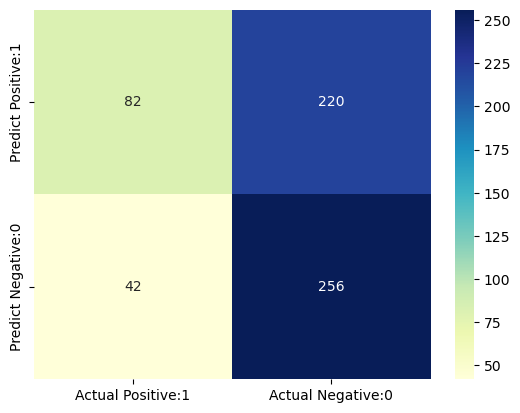

In [174]:
cm_matrix = pd.DataFrame(data=cm, columns=['Actual Positive:1', 'Actual Negative:0'], 
                                 index=['Predict Positive:1', 'Predict Negative:0'])

sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='YlGnBu')

##### Analizando la matriz de confusión:

- 1: default (incumplieron)
- 0: No default  (no incumplieron)

- De 256 + 42 = de 298 personas que se clasificaron como que  no incumplieron, 42 fueron clasificadas incorrectamente como que incumplieron (14%).
- De 220 + 82 = de 302 personas que se clasificaron como que  incumplieron, 220 fueron clasificadas incorrectamente como que cumplieron (72,8%).
- ¡Eso no es aceptable!
- ¡Vamos a arreglarlo! (al menos, intentarlo :/)

##### Encontrando los patrametros que minimizan el error de clasificacion. Utilizando GridSearchCV

Un Grid Search (o búsqueda en malla) es una técnica de optimización de hiperparámetros en machine learning.Es un procedimiento exhaustivo que prueba todas las combinaciones posibles de hiperparámetros dentro de un conjunto predefinido.

- C = [0.1, 1, 10]
- kernel = ['linear', 'rbf']

El Grid Search va a probar:

-C=0.1, kernel=linear

-C=0.1, kernel=rbf

-C=1, kernel=linear

-C=1, kernel=rbf

-C=10, kernel=linear

-C=10, kernel=rbf

In [2]:
from IPython.display import HTML, display

with open("grid_search_light.html", "r", encoding="utf-8") as f:
    html_content = f.read()

display(HTML(html_content))

In [94]:
param_grid = {'C':[0.5,0.1,1,10,100,1000], 'gamma':['scale', 1,0.1, 0.01,0.001,0.0001], 'kernel':['rbf']}
# we including C=1 and gamma = 'scale' cause these are default
# values;
# rbf = radial basis function, cause typically it gives us the best
# performance
# visit: Radial basis function 
optimal_params = GridSearchCV(SVC(), param_grid, cv = 5, scoring='accuracy', verbose=3)

In [96]:
optimal_params.fit(X_train_scaled, y_train)
print(optimal_params.best_params_)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
[CV 1/5] END ....C=0.5, gamma=scale, kernel=rbf;, score=0.689 total time=   0.1s
[CV 2/5] END ....C=0.5, gamma=scale, kernel=rbf;, score=0.693 total time=   0.1s
[CV 3/5] END ....C=0.5, gamma=scale, kernel=rbf;, score=0.725 total time=   0.1s
[CV 4/5] END ....C=0.5, gamma=scale, kernel=rbf;, score=0.707 total time=   0.1s
[CV 5/5] END ....C=0.5, gamma=scale, kernel=rbf;, score=0.696 total time=   0.1s
[CV 1/5] END ........C=0.5, gamma=1, kernel=rbf;, score=0.496 total time=   0.1s
[CV 2/5] END ........C=0.5, gamma=1, kernel=rbf;, score=0.532 total time=   0.1s
[CV 3/5] END ........C=0.5, gamma=1, kernel=rbf;, score=0.529 total time=   0.1s
[CV 4/5] END ........C=0.5, gamma=1, kernel=rbf;, score=0.525 total time=   0.1s
[CV 5/5] END ........C=0.5, gamma=1, kernel=rbf;, score=0.529 total time=   0.1s
[CV 1/5] END ......C=0.5, gamma=0.1, kernel=rbf;, score=0.582 total time=   0.1s
[CV 2/5] END ......C=0.5, gamma=0.1, kernel=rbf

El score mas alto fue [CV 3/5] END .......C=1, gamma=0.01, kernel=rbf;, score=0.721 total time=   0.1s


score=0.721 → Este es el puntaje de desempeño (por defecto, la métrica es accuracy para clasificación) del modelo en este fold específico. Es decir, el modelo acertó aproximadamente el 72.1% de las veces en los datos de validación del tercer fold.

In [98]:
clf_svm = SVC(random_state = 42, C=1, gamma=0.01)
clf_svm.fit(X_train_scaled, y_train)
SVC(C=1, break_ties=False, cache_size=200, class_weight=None, coef0=0.0,     decision_function_shape='ovr', degree=3, gamma=0.01, kernel='rbf',     max_iter=-1, probability=False, random_state=42, shrinking=True, tol=0.001,     verbose=False)

,C,1
,kernel,'rbf'
,degree,3
,gamma,0.01
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


##### Haciendo predicciónes

In [100]:
y_pred = clf_svm.predict(X_test_scaled)
# compute and print accuracy score
accuracy = accuracy_score(y_test, y_pred)
print('Model accuracy score with RBF kernel and C=1 : {0:0.4f}'.format(accuracy))

Model accuracy score with RBF kernel and C=1 : 0.6783


Observemos que con los hiperparametros optimos el accuracy aumento.

In [193]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print('Confusion matrix\n\n', cm)

print('\nTrue Positives(TP) = ', cm[0,0])

print('\nTrue Negatives(TN) = ', cm[1,1])

print('\nFalse Positives(FP) = ', cm[0,1])

print('\nFalse Negatives(FN) = ', cm[1,0])

Confusion matrix

 [[236  66]
 [127 171]]

True Positives(TP) =  236

True Negatives(TN) =  171

False Positives(FP) =  66

False Negatives(FN) =  127


<Axes: >

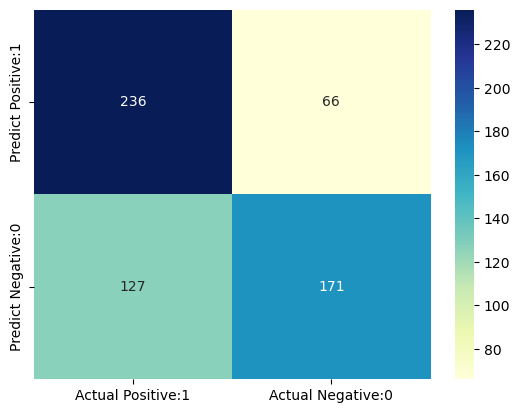

In [195]:
cm_matrix = pd.DataFrame(data=cm, columns=['Actual Positive:1', 'Actual Negative:0'], 
                                 index=['Predict Positive:1', 'Predict Negative:0'])

sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='YlGnBu')

In [197]:
len(df1_downsample.columns)

25

Esto requeriría un gráfico de 24 dimensiones. Eso es imposible… ¿cómo superar este problema?
La respuesta:PCA (Análisis de Componentes Principales). PCA es un algoritmo de aprendizaje no supervisado.

### Ejercicio 2

In [120]:
from google.colab import files

# Abrir ventana para seleccionar el archivo
uploaded = files.upload()

ModuleNotFoundError: No module named 'google.colab'

In [102]:
## Importación de la base
datos=pd.read_csv("Social_Network_Ads.csv")
datos.head()


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [104]:
###Separemos la base entre covariables y etiqueta
x = datos.iloc[:,2:4]
y = datos.iloc[:,-1]

In [106]:
# Split the data into training and test sets
SEED = 42  
X_train,X_test,y_train,y_test = train_test_split(x,y,test_size = 0.2,random_state=SEED)

In [108]:
# Scale the features using StandardScaler
scaler = StandardScaler()
#Ajustar el escalador (scaler) SOLO con el conjunto de entrenamiento
X_train = scaler.fit_transform(X_train)
#Transformar también el conjunto de prueba (usando la media y std de entrenamiento)
X_test = scaler.transform(X_test)

In [116]:
!python --version

Python 3.12.7


In [120]:
clf_svm = SVC(random_state = 42)
clf_svm.fit(X_train, y_train)


,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [122]:
# make predictions on test set
y_pred=clf_svm.predict(X_test)

# compute and print accuracy score
accuracy = accuracy_score(y_test, y_pred)
print('Model accuracy score with RBF kernel and C=1 : {0:0.4f}'.format(accuracy))

Model accuracy score with RBF kernel and C=1 : 0.9250


In [213]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print('Confusion matrix\n\n', cm)

print('\nTrue Positives(TP) = ', cm[0,0])

print('\nTrue Negatives(TN) = ', cm[1,1])

print('\nFalse Positives(FP) = ', cm[0,1])

print('\nFalse Negatives(FN) = ', cm[1,0])

Confusion matrix

 [[47  5]
 [ 1 27]]

True Positives(TP) =  47

True Negatives(TN) =  27

False Positives(FP) =  5

False Negatives(FN) =  1


<Axes: >

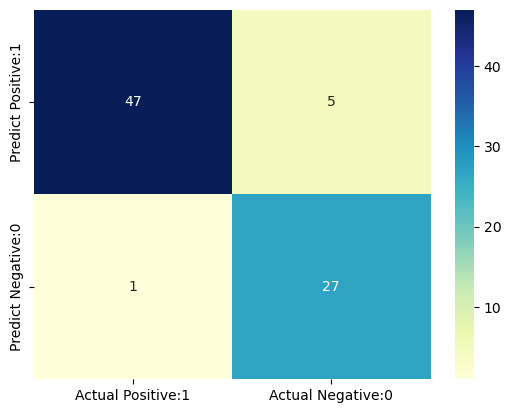

In [215]:
cm_matrix = pd.DataFrame(data=cm, columns=['Actual Positive:1', 'Actual Negative:0'], 
                                 index=['Predict Positive:1', 'Predict Negative:0'])

sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='YlGnBu')

In [217]:
##Accuracy
acc=metrics.accuracy_score(y_test,y_pred)
print("El accuracy score es " + str(acc))


##Recall
rec=metrics.recall_score(y_test,y_pred)
print("El recall score es " + str(rec))

##f1-score
f1=metrics.f1_score(y_test,y_pred)
print("El F1 score es " + str(f1))

El accuracy score es 0.925
El recall score es 0.9642857142857143
El F1 score es 0.9


## Ejercicio 3. Clasificacion

#### Cargando los datos

Estamos utilizando el conjunto de datos sobre cáncer de la biblioteca sklearn. Vamos a crear un clasificador para predecir si el cáncer es maligno o benigno. Podemos cargar el conjunto de datos de la siguiente manera.

La base fue recopilada en el Wisconsin Diagnostic Breast Cancer dataset (WDBC) por investigadores de la Universidad de Wisconsin.

- Contiene mediciones reales de imágenes digitalizadas de tejido mamario.

- Cada fila corresponde a un tumor en una paciente, y las columnas son características numéricas (por ejemplo: radio medio, textura, perímetro, área, etc.) extraídas de imágenes.

- El target indica si el tumor es maligno (0) o benigno (1).

- Son 569 observaciones con 30 características.

In [223]:
#Load dataset
cancer = datasets.load_breast_cancer()

# Convertir a DataFrame
df = pd.DataFrame(data=cancer.data, columns=cancer.feature_names)

# Agregar la columna objetivo (maligno/benigno)
df['target'] = cancer.target

In [225]:
print(cancer.DESCR)

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

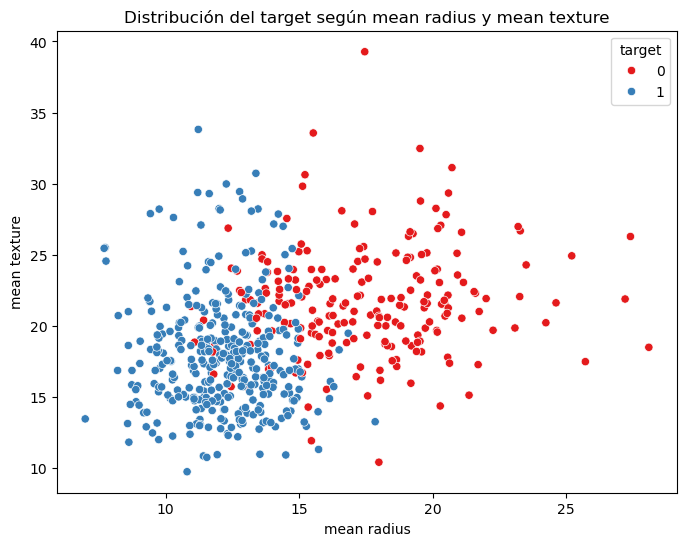

In [227]:
# Cargar dataset
cancer = datasets.load_breast_cancer()

# Convertir a DataFrame
df = pd.DataFrame(data=cancer.data, columns=cancer.feature_names)

# Agregar columna target
df['target'] = cancer.target

# Graficar dos variables con el target como color
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df,
    x="mean radius",   # variable en eje X
    y="mean texture",  # variable en eje Y
    hue="target",      # colorear por target
    palette="Set1"
)
plt.title("Distribución del target según mean radius y mean texture")
plt.show()

In [229]:
# print the cancer labels (0:malignant, 1:benign)
print(cancer.target)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 1 0 0 0 0 0 0 0 0 1 0 1 1 1 1 1 0 0 1 0 0 1 1 1 1 0 1 0 0 1 1 1 1 0 1 0 0
 1 0 1 0 0 1 1 1 0 0 1 0 0 0 1 1 1 0 1 1 0 0 1 1 1 0 0 1 1 1 1 0 1 1 0 1 1
 1 1 1 1 1 1 0 0 0 1 0 0 1 1 1 0 0 1 0 1 0 0 1 0 0 1 1 0 1 1 0 1 1 1 1 0 1
 1 1 1 1 1 1 1 1 0 1 1 1 1 0 0 1 0 1 1 0 0 1 1 0 0 1 1 1 1 0 1 1 0 0 0 1 0
 1 0 1 1 1 0 1 1 0 0 1 0 0 0 0 1 0 0 0 1 0 1 0 1 1 0 1 0 0 0 0 1 1 0 0 1 1
 1 0 1 1 1 1 1 0 0 1 1 0 1 1 0 0 1 0 1 1 1 1 0 1 1 1 1 1 0 1 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 1 1 1 1 1 1 0 1 0 1 1 0 1 1 0 1 0 0 1 1 1 1 1 1 1 1 1 1 1 1
 1 0 1 1 0 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0 1 0 1 1 1 1 0 0 0 1 1
 1 1 0 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 0 0 0 1 1 1 1 1 1 1 1 1 1 1 0 0 1 0 0
 0 1 0 0 1 1 1 1 1 0 1 1 1 1 1 0 1 1 1 0 1 1 0 0 1 1 1 1 1 1 0 1 1 1 1 1 1
 1 0 1 1 1 1 1 0 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 0 1 0 0 1 0 1 1 1 1 1 0 1 1
 0 1 0 1 1 0 1 0 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 0 1
 1 1 1 1 1 1 0 1 0 1 1 0 

In [231]:
frecuencias = df['target'].value_counts()
porcentajes = df['target'].value_counts(normalize=True)

# Combinar en un solo DataFrame
pd.DataFrame({'Frecuencia': frecuencias, 'Porcentaje': porcentajes})

,Frecuencia,Porcentaje
1,357,0.627417
0,212,0.372583


In [233]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


#### División de datos



In [236]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(cancer.data, cancer.target, test_size=0.3,random_state=109) # 70% training and 30% test

In [238]:
# check the shape of X_train and X_test

X_train.shape, X_test.shape

((398, 30), (171, 30))

#### Escalando caracteristicas

In [241]:
# Scale the features using StandardScaler
scaler = StandardScaler()
#Ajustar el escalador (scaler) SOLO con el conjunto de entrenamiento
X_train = scaler.fit_transform(X_train)
#Transformar también el conjunto de prueba (usando la media y std de entrenamiento)
X_test = scaler.transform(X_test)

#### Generación de modelo

Construyamos un modelo de máquina de vectores de soporte. Primero, importe el módulo SVM y cree un objeto clasificador de vectores de soporte pasando el argumento kernel como kernel lineal en la función SVC().
Luego, ajuste su modelo en el conjunto de entrenamiento usando fit() y realice una predicción en el conjunto de prueba usando predict().

In [244]:
#Create a svm Classifier
clf = SVC(random_state=42, kernel='linear') # Linear Kernel
#Train the model using the training sets
clf.fit(X_train, y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)
print(y_pred)


[1 1 0 0 1 0 1 1 1 0 0 0 1 0 1 1 0 0 1 0 1 1 0 0 1 1 0 1 1 1 1 0 1 1 1 1 1
 0 1 1 0 1 0 1 1 1 0 1 0 0 1 1 0 1 1 0 1 1 1 0 0 1 0 1 0 0 1 1 1 1 0 1 1 1
 0 1 0 1 1 1 1 1 1 1 0 1 1 1 1 1 0 1 1 0 1 1 1 1 1 0 0 1 1 0 1 1 0 1 0 1 1
 0 1 1 0 0 0 1 0 1 1 1 1 1 0 1 0 1 0 1 0 0 0 1 0 1 1 0 1 1 1 0 1 1 0 0 1 0
 0 0 1 1 1 1 1 0 0 1 0 1 1 1 1 1 1 1 1 0 1 1 1]


#### Evaluación del modelo

Estimemos con qué precisión el clasificador o el modelo pueden predecir el cáncer de mama de los pacientes. La precisión se puede calcular comparando los valores reales del conjunto de pruebas y los valores previstos

In [247]:
#Predict the response for test dataset
y_pred = clf.predict(X_test)
print(y_pred)

# Model Accuracy: how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

[1 1 0 0 1 0 1 1 1 0 0 0 1 0 1 1 0 0 1 0 1 1 0 0 1 1 0 1 1 1 1 0 1 1 1 1 1
 0 1 1 0 1 0 1 1 1 0 1 0 0 1 1 0 1 1 0 1 1 1 0 0 1 0 1 0 0 1 1 1 1 0 1 1 1
 0 1 0 1 1 1 1 1 1 1 0 1 1 1 1 1 0 1 1 0 1 1 1 1 1 0 0 1 1 0 1 1 0 1 0 1 1
 0 1 1 0 0 0 1 0 1 1 1 1 1 0 1 0 1 0 1 0 0 0 1 0 1 1 0 1 1 1 0 1 1 0 0 1 0
 0 0 1 1 1 1 1 0 0 1 0 1 1 1 1 1 1 1 1 0 1 1 1]
Accuracy: 0.9883040935672515


In [249]:
# Print the Confusion Matrix and slice it into four pieces
cm = confusion_matrix(y_test, y_pred)

print('Confusion matrix\n\n', cm)

print('\nTrue Positives(TP) = ', cm[0,0])

print('\nTrue Negatives(TN) = ', cm[1,1])

print('\nFalse Positives(FP) = ', cm[0,1])

print('\nFalse Negatives(FN) = ', cm[1,0])

Confusion matrix

 [[ 61   2]
 [  0 108]]

True Positives(TP) =  61

True Negatives(TN) =  108

False Positives(FP) =  2

False Negatives(FN) =  0


In [251]:
TP = cm[0,0]
TN = cm[1,1]
FP = cm[0,1]
FN = cm[1,0]

In [253]:
# print classification accuracy

classification_accuracy = (TP + TN) / float(TP + TN + FP + FN)

print('Classification accuracy : {0:0.4f}'.format(classification_accuracy))

Classification accuracy : 0.9883


In [255]:
# print classification error

classification_error = (FP + FN) / float(TP + TN + FP + FN)

print('Classification error : {0:0.4f}'.format(classification_error))

Classification error : 0.0117


In [257]:
recall = TP / float(TP + FN)

print('Recall or Sensitivity : {0:0.4f}'.format(recall))

Recall or Sensitivity : 1.0000


<Axes: >

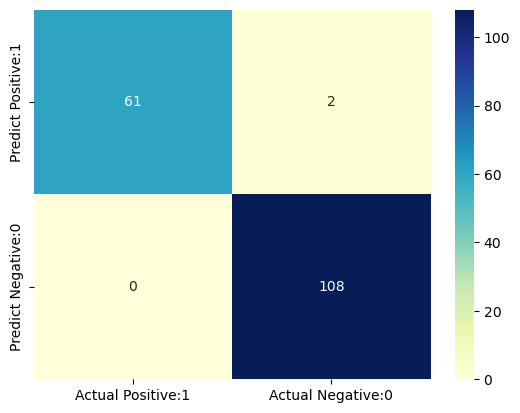

In [259]:
# visualize confusion matrix with seaborn heatmap

cm_matrix = pd.DataFrame(data=cm, columns=['Actual Positive:1', 'Actual Negative:0'], 
                                 index=['Predict Positive:1', 'Predict Negative:0'])

sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='YlGnBu')

#### Hyperparameter Optimization using GridSearch CV

In [262]:
# instantiate classifier with default hyperparameters with kernel=rbf, C=1.0 and gamma=auto
svc=SVC() 



# declare parameters for hyperparameter tuning
parameters = [ {'C':[1, 10, 100, 1000], 'kernel':['linear']},
               {'C':[1, 10, 100, 1000], 'kernel':['rbf'], 'gamma':[0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 'scale']},
               {'C':[1, 10, 100, 1000], 'kernel':['poly'], 'degree': [2,3,4] ,'gamma':[0.01,0.02,0.03,0.04,0.05, 'scale' ]} 
              ]




grid_search = GridSearchCV(estimator = svc,  
                           param_grid = parameters,
                           scoring = 'accuracy',
                           cv = 5,
                           verbose=False)


grid_search.fit(X_train, y_train)

,estimator,SVC()
,param_grid,"[{'C': [1, 10, ...], 'kernel': ['linear']}, {'C': [1, 10, ...], 'gamma': [0.1, 0.2, ...], 'kernel': ['rbf']}, ...]"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,False
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,10


In [263]:
# examine the best model

# print parameters that give the best results
print('Parameters that give the best results :','\n\n', (grid_search.best_params_))


# print estimator that was chosen by the GridSearch
print('\n\nEstimator that was chosen by the search :','\n\n', (grid_search.best_estimator_))

Parameters that give the best results : 

 {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}


Estimator that was chosen by the search : 

 SVC(C=10)


In [264]:
# calculate GridSearch CV score on test set

print('GridSearch CV score on test set: {0:0.4f}'.format(grid_search.score(X_test, y_test)))

GridSearch CV score on test set: 0.9883


In [265]:
# Definir el modelo correctamente
clf_svm = SVC(random_state=42, C=10, gamma="scale", kernel="rbf")

# Entrenar el modelo
clf_svm.fit(X_train, y_train)

# Hacer predicciones
y_pred = clf_svm.predict(X_test)


In [266]:
# Model Accuracy: how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

Accuracy: 0.9883040935672515


Los datos son linealmente separables (o casi)
Si el  dataset tiene una frontera de decisión lineal clara, entonces un kernel lineal ya es suficiente.
El kernel RBF, aunque es más flexible, termina aprendiendo prácticamente la misma frontera, luego arroja el  mismo accuracy.

### Ejercicio 4. Detectando fraude financiero con SVM (Suppor Vector Machine)

In [124]:
data = pd.read_csv('PS_20174392719_1491204439457_log.csv')
data.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [138]:
data = data.sample(n=100000, random_state=42)  # Saca 100000 observaciones aleatorias

In [140]:
df = data.copy()

In [142]:
print(df.isnull().sum())

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64


In [144]:
# checking whether the data is balanced or not. 
# and it seems the dataset is imbalanced, so to deal with imbalanceness we will introduce class_weights while building the model

df['isFraud'].value_counts()

isFraud
0    99859
1      141
Name: count, dtype: int64

### Dividiendo la muestra en train y test

In [158]:
# deleting the unnecessary varibles from input data

X = df.drop(columns=['step', 'newbalanceDest','oldbalanceOrg','nameOrig','nameDest','isFlaggedFraud','isFraud'])

X.head()

,type,amount,newbalanceOrig,oldbalanceDest
2174997,CASH_IN,192669.65,193063.65,3446197.37
3542033,CASH_OUT,125122.34,0.00,0.00
2937719,CASH_OUT,373469.53,0.00,428983.68
329089,CASH_OUT,124197.42,0.00,59064.41
1377386,CASH_IN,109384.86,123624.86,132880.24


In [160]:
y = df['isFraud']
y.head()

2174997    0
3542033    0
2937719    0
329089     0
1377386    0
Name: isFraud, dtype: int64

In [162]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

### 3. Data Preprocessing
##### Handling Categorical -  One Hot Encoding

In [165]:
# Ejemplo de casting de variables
dummies_type = pd.get_dummies(X_train['type'], prefix='type', drop_first=True)
X_train = pd.concat([X_train, dummies_type.astype(int)], axis=1)
X_train.head()

,type,amount,newbalanceOrig,oldbalanceDest,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
362139,PAYMENT,21334.92,168986.08,0.00,0,0,1,0
4265355,CASH_IN,188524.54,272188.99,992044.41,0,0,0,0
3529963,CASH_IN,1489.63,277323.48,43198.09,0,0,0,0
3077568,CASH_OUT,105981.52,0.00,860727.46,1,0,0,0
5093838,CASH_OUT,3702.51,986098.49,0.00,1,0,0,0


Como ya tengo las variables dicotomicas por cada tipo (type) de transaccion ya no necesito a la variable type.

In [168]:
X_train = X_train.drop(columns=['type'])
X_train.head()

,amount,newbalanceOrig,oldbalanceDest,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
362139,21334.92,168986.08,0.00,0,0,1,0
4265355,188524.54,272188.99,992044.41,0,0,0,0
3529963,1489.63,277323.48,43198.09,0,0,0,0
3077568,105981.52,0.00,860727.46,1,0,0,0
5093838,3702.51,986098.49,0.00,1,0,0,0


In [170]:
dummies_type = pd.get_dummies(X_test['type'], prefix='type', drop_first=True)
X_test = pd.concat([X_test, dummies_type.astype(int)], axis=1)
X_test = X_test.drop(columns=['type'])
X_test.head()

,amount,newbalanceOrig,oldbalanceDest,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
194371,1308.92,4743.54,0.00,0,0,1,0
441009,76379.90,92818.65,82706.35,1,0,0,0
1274135,219101.03,0.00,1056293.44,1,0,0,0
1257899,9058.01,103055.51,0.00,0,0,1,0
284070,29164.58,0.00,52231.03,1,0,0,0


In [172]:
### Aplicacion valores booleanos
(X_train.columns == X_test.columns).all()

True

### 4. Model Building. SVM  Model implementation

In [175]:
from sklearn.svm import SVC

clf_svm = SVC(
    random_state=42,
    class_weight="balanced",  # Ajusta los pesos según el desbalance
    kernel="rbf",             # Kernel RBF (default)
    gamma="scale"             # Recomendado para adaptar automáticamente
)

clf_svm.fit(X_train, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,'balanced'
,verbose,False


In [46]:
# make predictions on test set
y_pred=clf_svm.predict(X_test)

# compute and print accuracy score
accuracy = accuracy_score(y_test, y_pred)
print('Model accuracy score with RBF kernel and C=1 : {0:0.4f}'.format(accuracy))

Model accuracy score with RBF kernel and C=1 : 0.9340


#### Hyperparameter Optimization using GridSearch CV

In [ ]:
# instantiate classifier with default hyperparameters with kernel=rbf, C=1.0 and gamma=auto
svc=SVC() 



# declare parameters for hyperparameter tuning
parameters = [ {'C':[1, 10, 100, 1000], 'kernel':['linear']},
               {'C':[1, 10, 100, 1000], 'kernel':['rbf'], 'gamma':[0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 'scale']},
               {'C':[1, 10, 100, 1000], 'kernel':['poly'], 'degree': [2,3,4] ,'gamma':[0.01,0.02,0.03,0.04,0.05, 'scale' ]} 
              ]




grid_search = GridSearchCV(estimator = svc,  
                           param_grid = parameters,
                           scoring = 'accuracy',
                           cv = 5,
                           verbose=False)


grid_search.fit(X_train, y_train)